# TODO

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder

In [9]:
df = pd.read_csv("/Users/abhimanyuchettiar/Desktop/career/churn-prediction/data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [10]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [11]:
internet_types = df['InternetService'].unique()


In [12]:
internet_types

array(['DSL', 'Fiber optic', 'No'], dtype=object)

In [13]:
payment_types = df['PaymentMethod'].unique()
payment_types

array(['Electronic check', 'Mailed check', 'Bank transfer (automatic)',
       'Credit card (automatic)'], dtype=object)

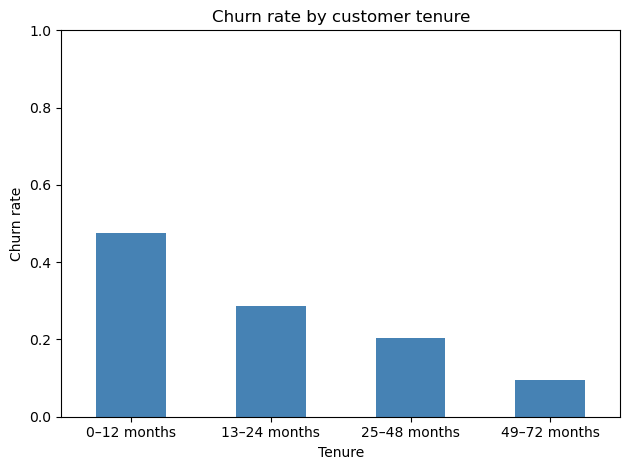

tenure_group
0–12 months     47.4
13–24 months    28.7
25–48 months    20.4
49–72 months     9.5
Name: churned, dtype: float64


In [14]:
bins = [0, 12, 24, 48, 72]
labels = ["0–12 months", "13–24 months", "25–48 months", "49–72 months"]

df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

churn_rate = (
    df.assign(churned=df["Churn"].eq("Yes"))
      .groupby("tenure_group", observed=False)["churned"]
      .mean()
)

churn_rate.plot(kind="bar", color="steelblue")
plt.ylabel("Churn rate")
plt.xlabel("Tenure")
plt.title("Churn rate by customer tenure")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

print((churn_rate * 100).round(1))